# 06. Spatial Autocorrelation, Unsupervised Mining & Vulnerability Index
## Sub-Catchment Spatial Intelligence & Policy Prioritization (Kavrepalanchok District, Nepal)

### Scientific Context & Objectives
This notebook executes the spatial data mining and policy prioritization pipeline for the 5,689 surveyed springs in Kavrepalanchok:
1. **Multi-Scale Spatial Autocorrelation & Distance Decay**: Quantifies how desiccation spatial dependence decays across geometric scales ($k \in [3, 20]$), determining the empirical sub-catchment fracture flow boundary.
2. **Anselin's Local Moran's I (LISA) Hotspots**: Detects statistically significant local clusters of desiccation (High-High cores) and imminent hazard outliers (Low-High vulnerable springs) with Benjamini-Hochberg False Discovery Rate (FDR) control.
3. **Hydro-Ecological Association Rule Mining**: Discovers frequent multi-factor environmental patterns associated with spring desiccation using Fisher's exact tests and BH-FDR correction over all candidate rules.
4. **Actionable Spring Prioritization Index (SPI / HSVI)**: Couples machine-learning predicted drying risk with household dependency to rank the **Top 500 critically endangered active springs** for municipal engineering interventions.

In [1]:
import os, sys
from pathlib import Path

# Setup project root and headless matplotlib environment
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "kavre_springs" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.environ["MPLCONFIGDIR"] = os.path.join(str(PROJECT_ROOT), ".matplotlib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.graph_builder import load_master, coords_to_metric
from src.spatial_mining import knn_weights, morans_i, lisa, quad_label, bh_fdr, association_rules

print("Geospatial & Spatial Mining libraries loaded successfully.")

Geospatial & Spatial Mining libraries loaded successfully.


In [2]:
# Load master dataset and convert geographic coordinates to local UTM metric space (meters)
df_master = load_master()
coords_m = coords_to_metric(df_master["latitude"].to_numpy(), df_master["longitude"].to_numpy())
y = df_master["target_dried"].to_numpy(float)

num_total = len(df_master)
num_dried = int(y.sum())
num_active = num_total - num_dried

print("=== Kavrepalanchok Mountain Spring Survey Geometry ===")
print(f"Total Water Sources: {num_total:,}")
print(f"Dried Sources:       {num_dried:,} ({y.mean():.1%})")
print(f"Active Sources:      {num_active:,} ({(1 - y.mean()):.1%})")
print(f"Spatial Extent:      ~40 km East-West x 39 km North-South")

=== Kavrepalanchok Mountain Spring Survey Geometry ===
Total Water Sources: 5,689
Dried Sources:       1,521 (26.7%)
Active Sources:      4,168 (73.3%)
Spatial Extent:      ~40 km East-West x 39 km North-South


## 1. Multi-Scale Spatial Autocorrelation & Distance Decay

We compute Global Moran's $I$ across varying $k$-nearest neighbor radii ($k \in [3, 5, 7, 10, 15, 20]$) using 999 permutation trials to establish the physical scale of desiccation.

Computing Global Moran's I across spatial scales (k=3 to k=20)...
  k= 3 (mean d=162.5m) | Moran's I: 0.2788 | z-score: 27.34 (p=0.001)
  k= 5 (mean d=216.0m) | Moran's I: 0.2444 | z-score: 30.82 (p=0.001)
  k= 7 (mean d=262.0m) | Moran's I: 0.2234 | z-score: 33.36 (p=0.001)
  k=10 (mean d=321.7m) | Moran's I: 0.2043 | z-score: 36.77 (p=0.001)
  k=15 (mean d=405.3m) | Moran's I: 0.1888 | z-score: 41.25 (p=0.001)
  k=20 (mean d=477.0m) | Moran's I: 0.1792 | z-score: 45.43 (p=0.001)
   k_neighbors  mean_neighbor_dist_m  morans_i  z_score  p_value
0            3                 162.5    0.2788    27.34    0.001
1            5                 216.0    0.2444    30.82    0.001
2            7                 262.0    0.2234    33.36    0.001
3           10                 321.7    0.2043    36.77    0.001
4           15                 405.3    0.1888    41.25    0.001
5           20                 477.0    0.1792    45.43    0.001


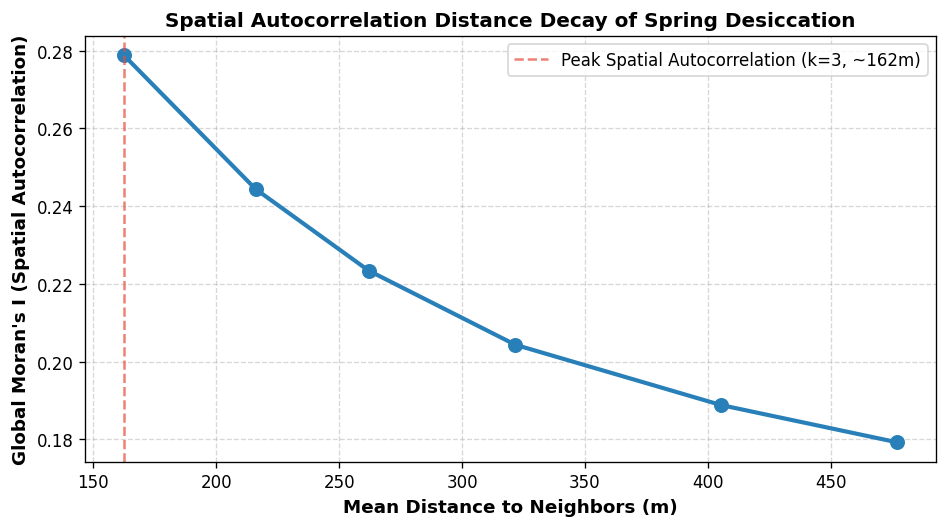

In [4]:
k_values = [3, 5, 7, 10, 15, 20]
decay_records = []
rng = np.random.default_rng(2024)

print("Computing Global Moran's I across spatial scales (k=3 to k=20)...")
for k in k_values:
    W, mean_d, _ = knn_weights(coords_m, k)
    I_val, p_val, z_val = morans_i(y, W, n_perm=999, rng=rng)
    decay_records.append({
        "k_neighbors": k,
        "mean_neighbor_dist_m": round(mean_d, 1),
        "morans_i": round(float(I_val), 4),
        "z_score": round(float(z_val), 2),
        "p_value": float(p_val)
    })
    print(f"  k={k:2d} (mean d={mean_d:5.1f}m) | Moran's I: {I_val:.4f} | z-score: {z_val:.2f} (p={p_val:.3f})")

df_decay = pd.DataFrame(decay_records)
display(df_decay)

# Plot Multi-Scale Distance Decay
plt.figure(figsize=(8, 4.5), dpi=300)
plt.plot(df_decay["mean_neighbor_dist_m"], df_decay["morans_i"], marker='o', linewidth=2.5, markersize=8, color="#2980b9")
plt.axvline(df_decay.loc[0, "mean_neighbor_dist_m"], color='#e74c3c', linestyle='--', alpha=0.7, 
            label=f"Peak Spatial Autocorrelation (k=3, ~{df_decay.loc[0, 'mean_neighbor_dist_m']:.0f}m)")
plt.xlabel("Mean Distance to Neighbors (m)", fontsize=11, fontweight="bold")
plt.ylabel("Global Moran's I (Spatial Autocorrelation)", fontsize=11, fontweight="bold")
plt.title("Spatial Autocorrelation Distance Decay of Spring Desiccation", fontsize=12, fontweight="bold")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
os.makedirs(PROJECT_ROOT / "results/figures", exist_ok=True)
plt.savefig(PROJECT_ROOT / "results/figures/spatial_mining_diagnostics.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Anselin's Local Moran's I (LISA) Hotspot Analysis

We detect spatial clusters and local spatial outliers at $k=7$ using conditional permutations and Benjamini-Hochberg False Discovery Rate (FDR) correction:
- **High-High**: Desiccation core hotspots.
- **Low-High**: Active springs in dried clusters (imminent risk outliers).
- **Low-Low**: Hydrologically secure coldspots.
- **High-Low**: Isolated dried springs.

=== Anselin's Local Moran's I (BH-FDR q < 0.05) Cluster Summary ===
                    Cluster Type  Spring Count
0                Not significant          5564
1      High-High (dried cluster)            95
2  Low-High (active among dried)            30


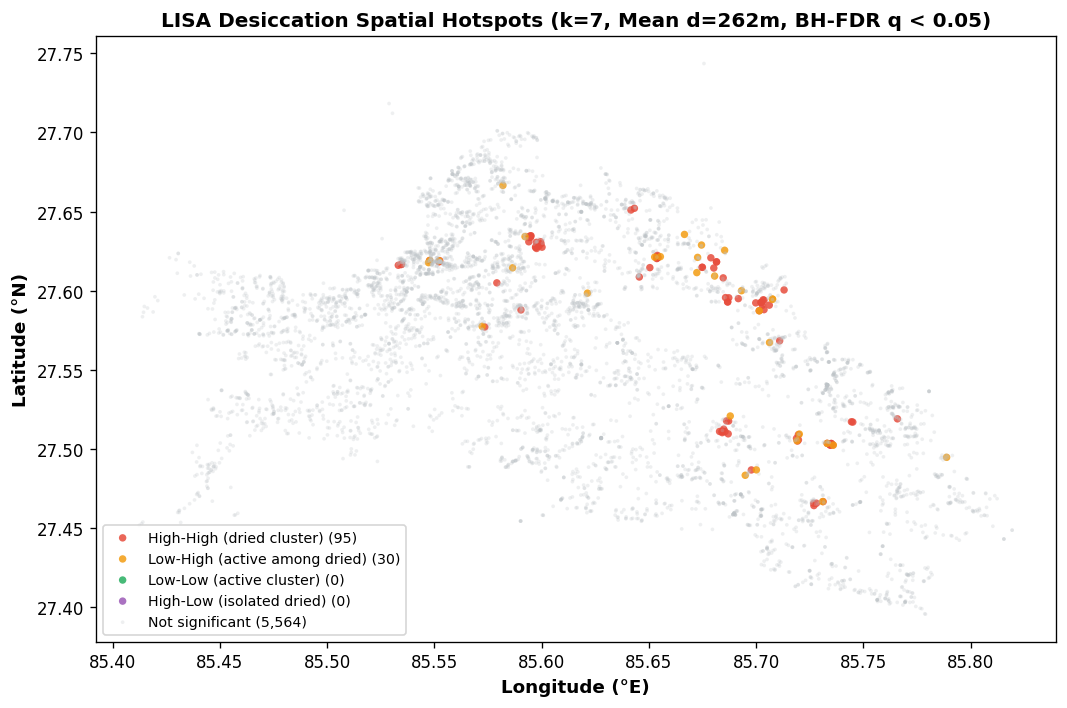

In [6]:
W7, mean_d7, nbr7 = knn_weights(coords_m, 7)
Ii, p_sim, q_fdr, quad = lisa(y, W7, nbr7, n_perm=999, rng=rng)

df_master["local_moran_i"] = Ii
df_master["p_value_sim"] = p_sim
df_master["q_value_fdr"] = q_fdr
df_master["lisa_cluster"] = quad

print("=== Anselin's Local Moran's I (BH-FDR q < 0.05) Cluster Summary ===")
lisa_summary = df_master["lisa_cluster"].value_counts().reset_index()
lisa_summary.columns = ["Cluster Type", "Spring Count"]
display(lisa_summary)

# Plot Spatial LISA Clusters
plt.figure(figsize=(9, 6), dpi=300)
colors_lisa = {
    "High-High (dried cluster)": "#e74c3c", 
    "Low-High (active among dried)": "#f39c12", 
    "Low-Low (active cluster)": "#27ae60", 
    "High-Low (isolated dried)": "#9b59b6", 
    "Not significant": "#bdc3c7"
}

for ctype, col in colors_lisa.items():
    sub = df_master[df_master["lisa_cluster"] == ctype]
    alpha = 0.85 if ctype != "Not significant" else 0.25
    size = 20 if ctype != "Not significant" else 5
    plt.scatter(sub["longitude"], sub["latitude"], c=col, label=f"{ctype} ({len(sub):,})", s=size, alpha=alpha, edgecolors='none')

plt.xlabel("Longitude (°E)", fontsize=11, fontweight="bold")
plt.ylabel("Latitude (°N)", fontsize=11, fontweight="bold")
plt.title(f"LISA Desiccation Spatial Hotspots (k=7, Mean d={mean_d7:.0f}m, BH-FDR q < 0.05)", fontsize=12, fontweight="bold")
plt.legend(frameon=True, loc="lower left", fontsize=8.5)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results/figures/lisa_cluster_map.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Hydro-Ecological Association Rule Mining

We discover frequent multi-factor environmental and landscape conditions strongly associated with spring drying (*target_dried = 1*) using Fisher's exact test and Benjamini-Hochberg FDR control across all evaluated candidate rules.

=== Top Hydro-Ecological Association Rules for Spring Desiccation (BH-FDR q < 0.05) ===
                                                              antecedent  n_antecedent  n_dried  support  confidence    lift  odds_ratio  q_value_bh
0                 Seasonal spring [timing-confounded] AND Slope > 25 deg           281      186   0.0327      0.6619  2.4758      5.9734         0.0
1              Seasonal spring [timing-confounded] AND Source type: pond           239      158   0.0278      0.6611  2.4727      5.8490         0.0
2             Seasonal spring [timing-confounded] AND Elevation < 1100 m           203      129   0.0227      0.6355  2.3768      5.1270         0.0
3  Seasonal spring [timing-confounded] AND Spring density > 10 per 500 m           548      348   0.0612      0.6350  2.3752      5.8860         0.0
4                                    Seasonal spring [timing-confounded]           930      587   0.1032      0.6312  2.3608      7.0086         0.0
5     Seasonal spr

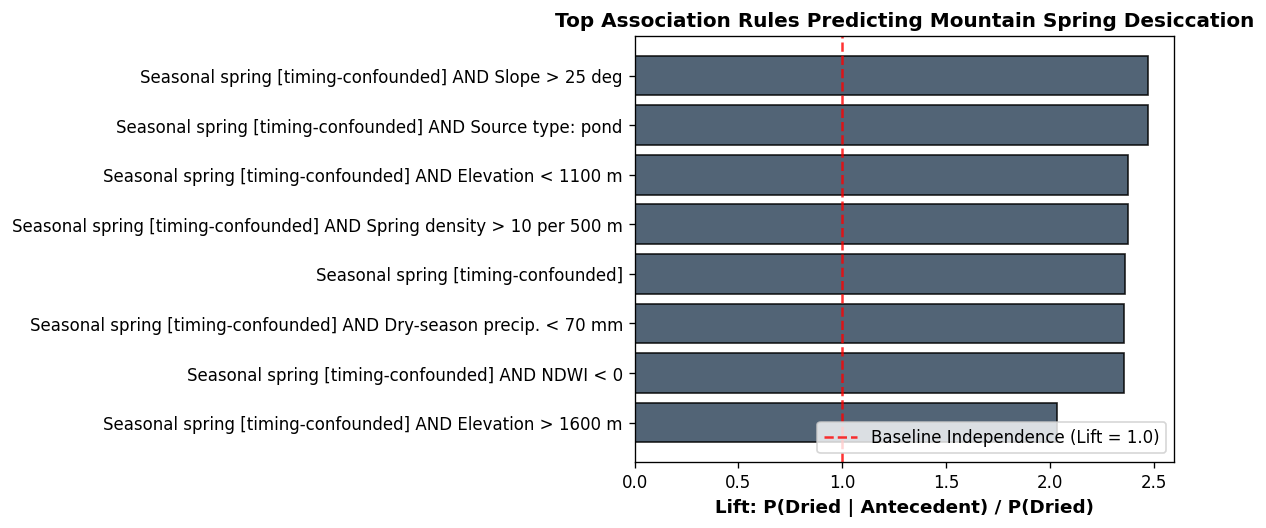

In [8]:
rules = association_rules(df_master, min_support=0.03)

print("=== Top Hydro-Ecological Association Rules for Spring Desiccation (BH-FDR q < 0.05) ===")
sig_rules = rules[rules["q_value_bh"] < 0.05].head(10).copy()
display(sig_rules[["antecedent", "n_antecedent", "n_dried", "support", "confidence", "lift", "odds_ratio", "q_value_bh"]].round(4))

# Plot Association Rule Lifts
plt.figure(figsize=(10, 4.5), dpi=300)
top_plot = sig_rules.head(8).iloc[::-1]
plt.barh(top_plot["antecedent"], top_plot["lift"], color="#34495e", edgecolor="black", alpha=0.85)
plt.axvline(1.0, color="red", linestyle="--", alpha=0.8, label="Baseline Independence (Lift = 1.0)")
plt.xlabel("Lift: P(Dried | Antecedent) / P(Dried)", fontsize=11, fontweight="bold")
plt.title("Top Association Rules Predicting Mountain Spring Desiccation", fontsize=12, fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. Active Spring Prioritization Index (SPI) & Actionable Interventions

We couple model susceptibility with community exposure to rank the **Top 500 critically endangered active springs** for municipal engineering interventions:
$$\text{SPI}_i = \text{Rank}_{\%}(\hat{P}_{\text{dry}, i}) \times \text{Rank}_{\%}(D_{\text{hh}, i})$$
where $\hat{P}_{\text{dry}, i}$ is the out-of-fold predicted desiccation probability from our top-performing model, and $D_{\text{hh}, i}$ is the total dependent household population.

In [10]:
from src.prioritization import run_prioritization

# Execute full prioritization pipeline
muni_summary, sens = run_prioritization(top_n=500)

print("=== Municipality Spring Priority Summary (Top 500 Active Springs) ===")
display(muni_summary.round(3))

print("\n=== Priority Index Sensitivity Analysis ===")
display(sens.T)

=== Municipality Spring Priority Summary (Top 500 Active Springs) ===
   municipality  total_sources  dried  drying_rate  active_ranked  mean_susceptibility  households_dependent  in_top_500
0  Bethanchownk            385     74        0.192            243                0.237                7461.0           1
1     Dhulikhel           1174    338        0.288            633                0.428                7455.0          68
2    Namobuudha            478     96        0.201            324                0.472                9465.0         100
3       Panauti            880     83        0.094            664                0.284               15815.0           9
4     Panchkhal           1067    426        0.399            549                0.498               12589.0         151
5      Roshi RM            969    211        0.218            492                0.399                8464.0          46
6         Temal            736    293        0.398            301                0.